# 03 - Stacking

Ensemble Stacking con los 10 modelos de la Tarea 2 como modelos débiles: 5 ejecuciones con CV (Tarea 3).

**Decisiones del grupo:**
- **Modelos base:** los 10 modelos de la Tarea 2 (T1–T5 y L1–L5) con los mismos hiperparámetros. Cada uno le entrega al meta-modelo una **probabilidad** (`stack_method='predict_proba'`).
- **5 ejecuciones:** se varía el **meta-modelo** (regresión logística o árbol, y sus hiperparámetros) y si recibe o no las variables originales (`passthrough`).
- **Cross-validation externo:** los **mismos 10 folds** de la Tarea 2, para que la comparación sea justa.
- **Cross-validation interno:** 5 folds estratificados, para entrenar al meta-modelo con predicciones sobre datos que los modelos base no vieron.
- **`Student ID`:** target encoding dentro de cada fold, igual que en la Tarea 2.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))  # para poder importar src/

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import TargetEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import StackingClassifier
from sklearn.metrics import ConfusionMatrixDisplay

from src.utils import TARGET, DATOS_PROCESADOS, RAIZ

RESULTADOS = RAIZ / 'resultados'
SEMILLA = 42

## 1. Carga de datos

Se usa el mismo conjunto de columnas elegido en el notebook 02: **sin keywords (48 columnas)**.

In [2]:
df = pd.read_csv(DATOS_PROCESADOS / 'datos_procesados.csv')

X = df.drop(columns=TARGET)
X = X[[c for c in X.columns if not c.startswith('KW_')]]  # conjunto A: sin keywords
y = df[TARGET]

print('X:', X.shape, '| y:', y.shape)

X: (9546, 48) | y: (9546,)


## 2. Esquema de evaluación

El Stacking tiene **dos niveles** de cross-validation:

- **CV externo (10 folds):** mide el rendimiento del ensemble completo. Son exactamente los mismos folds que en la Tarea 2 (misma semilla), así que todos los modelos se evalúan sobre las mismas particiones.
- **CV interno (5 folds):** dentro de cada fold de entrenamiento, el Stacking entrena los modelos base en 4 partes y predice la quinta. Así el meta-modelo aprende a partir de predicciones sobre datos que los modelos base **no vieron**. Si usara predicciones sobre datos de entrenamiento, confiaría de más en los modelos que memorizan (como el árbol sin límite, T5).

El target encoding de `Student ID` se aplica **una sola vez, antes del Stacking**, dentro del pipeline: en cada fold externo se calcula solo con los datos de entrenamiento.

In [3]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEMILLA)          # mismo que en la Tarea 2
cv_interno = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)   # para entrenar al meta-modelo

METRICAS = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']


def crear_pipeline(modelo):
    """Target encoding de Student ID (dentro de cada fold) + modelo."""
    encoder = ColumnTransformer(
        [('te_student', TargetEncoder(target_type='binary',
                                      cv=StratifiedKFold(5, shuffle=True, random_state=SEMILLA)),
          ['Student ID'])],
        remainder='passthrough',
    )
    return make_pipeline(encoder, modelo)


def evaluar(nombre, modelo, X, y):
    """Evalúa un modelo con cross-validation y devuelve el promedio y el desvío de cada métrica."""
    res = cross_validate(crear_pipeline(modelo), X, y, cv=cv, scoring=METRICAS)
    fila = {'modelo': nombre}
    for m in METRICAS:
        fila[m] = res[f'test_{m}'].mean()
        fila[f'{m}_std'] = res[f'test_{m}'].std()
    return fila


def ic95(valores):
    """Media e intervalo de confianza del 95 % (distribución t de Student)."""
    valores = np.asarray(valores)
    n = len(valores)
    media = valores.mean()
    margen = stats.t.ppf(0.975, n - 1) * valores.std(ddof=1) / np.sqrt(n)
    return media, media - margen, media + margen


def resumen_tecnica(res):
    """Promedio de cada métrica entre las configuraciones, con su IC 95 %."""
    filas = {}
    for m in METRICAS:
        media, inf, sup = ic95(res[m])
        filas[m] = {'media': media, 'IC95 inf': inf, 'IC95 sup': sup}
    return pd.DataFrame(filas).T

## 3. Modelos base (los 10 de la Tarea 2)

| Árbol de decisión | Regresión logística |
|---|---|
| T1: `max_depth=3` | L1: `C=0.01` |
| T2: `max_depth=5` | L2: `C=0.1` |
| T3: `max_depth=8`, `min_samples_leaf=20` | L3: `C=1` |
| T4: `max_depth=12`, `min_samples_leaf=10`, `criterion='entropy'` | L4: `C=10` |
| T5: sin límite de profundidad | L5: `C=1`, penalización L1 |

In [4]:
modelos_base = [
    ('T1', DecisionTreeClassifier(max_depth=3, random_state=SEMILLA)),
    ('T2', DecisionTreeClassifier(max_depth=5, random_state=SEMILLA)),
    ('T3', DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, random_state=SEMILLA)),
    ('T4', DecisionTreeClassifier(max_depth=12, min_samples_leaf=10, criterion='entropy', random_state=SEMILLA)),
    ('T5', DecisionTreeClassifier(max_depth=None, random_state=SEMILLA)),
    ('L1', LogisticRegression(C=0.01, max_iter=2000)),
    ('L2', LogisticRegression(C=0.1, max_iter=2000)),
    ('L3', LogisticRegression(C=1, max_iter=2000)),
    ('L4', LogisticRegression(C=10, max_iter=2000)),
    ('L5', LogisticRegression(C=1, l1_ratio=1, solver='liblinear', max_iter=2000)),
]


def crear_stacking(meta_modelo, passthrough=False):
    """Stacking con los 10 modelos base y el meta-modelo indicado."""
    return StackingClassifier(
        estimators=modelos_base,
        final_estimator=meta_modelo,
        stack_method='predict_proba',  # cada modelo base aporta su probabilidad de "correcta"
        cv=cv_interno,
        passthrough=passthrough,       # True: el meta-modelo también ve las variables originales
        n_jobs=-1,
    )

## 4. Las 5 ejecuciones del Stacking

Se varía el meta-modelo: lineal (regresión logística) o basado en reglas (árbol), y si recibe solo las predicciones de los modelos base o también las variables originales (`passthrough`).

| Config. | Meta-modelo | `passthrough` |
|---|---|---|
| S1 | Regresión logística, `C=1` | No |
| S2 | Regresión logística, `C=0.01` (más regularización) | No |
| S3 | Regresión logística, `C=1` | Sí |
| S4 | Árbol, `max_depth=3` | No |
| S5 | Árbol, `max_depth=5` | Sí |

In [5]:
stackings = {
    'S1 meta RL C=1': crear_stacking(LogisticRegression(C=1, max_iter=2000)),
    'S2 meta RL C=0.01': crear_stacking(LogisticRegression(C=0.01, max_iter=2000)),
    'S3 meta RL C=1 + passthrough': crear_stacking(LogisticRegression(C=1, max_iter=2000), passthrough=True),
    'S4 meta árbol depth=3': crear_stacking(DecisionTreeClassifier(max_depth=3, random_state=SEMILLA)),
    'S5 meta árbol depth=5 + passthrough': crear_stacking(DecisionTreeClassifier(max_depth=5, random_state=SEMILLA),
                                                          passthrough=True),
}

res_stack = pd.DataFrame([evaluar(n, m, X, y) for n, m in stackings.items()]).set_index('modelo')
display(res_stack[METRICAS].round(3))

,accuracy,precision,recall,f1,roc_auc
modelo,,,,,
S1 meta RL C=1,0.653,0.625,0.647,0.636,0.708
S2 meta RL C=0.01,0.655,0.629,0.640,0.634,0.708
S3 meta RL C=1 + passthrough,0.651,0.621,0.653,0.637,0.706
S4 meta árbol depth=3,0.647,0.633,0.589,0.609,0.695
S5 meta árbol depth=5 + passthrough,0.651,0.622,0.665,0.640,0.698


## 5. Promedio de las 5 ejecuciones (Tarea 3.b)

In [6]:
prom_stack = resumen_tecnica(res_stack)
display(prom_stack.round(3))

,media,IC95 inf,IC95 sup
accuracy,0.651,0.648,0.655
precision,0.626,0.620,0.633
recall,0.639,0.602,0.675
f1,0.631,0.615,0.647
roc_auc,0.703,0.696,0.710


## 6. Comparación con la Tarea 2 (Tarea 3.c)

Se leen los resultados guardados por el notebook 02 (hay que correrlo antes).

In [7]:
res_t2 = pd.read_csv(RESULTADOS / 'resultados_tarea2.csv', index_col='modelo')
prom_t2 = pd.read_csv(RESULTADOS / 'promedios_tarea2.csv', header=[0, 1], index_col=0)

# Promedio de las 5 configuraciones de cada técnica, con su IC 95 %
promedios = pd.concat({'Árbol de decisión': prom_t2['Árbol de decisión'],
                       'Regresión logística': prom_t2['Regresión logística'],
                       'Stacking': prom_stack}, axis=1)
display(promedios.round(3))

# Mejor configuración de cada técnica (según AUC)
mejores = pd.concat([
    res_t2[res_t2['tecnica'] == 'Árbol'][METRICAS].sort_values('roc_auc').tail(1),
    res_t2[res_t2['tecnica'] == 'Reg. logística'][METRICAS].sort_values('roc_auc').tail(1),
    res_stack[METRICAS].sort_values('roc_auc').tail(1),
])
display(mejores.round(3))

Árbol de decisión                   Regresión logística           \
                      media IC95 inf IC95 sup               media IC95 inf   
accuracy              0.639    0.619    0.660               0.650    0.645   
precision             0.614    0.596    0.633               0.634    0.625   
recall                0.621    0.570    0.673               0.596    0.544   
f1                    0.617    0.585    0.648               0.613    0.588   
roc_auc               0.679    0.635    0.724               0.705    0.703   

                   Stacking                    
          IC95 sup    media IC95 inf IC95 sup  
accuracy     0.655    0.651    0.648    0.655  
precision    0.643    0.626    0.620    0.633  
recall       0.648    0.639    0.602    0.675  
f1           0.639    0.631    0.615    0.647  
roc_auc      0.707    0.703    0.696    0.710

,accuracy,precision,recall,f1,roc_auc
modelo,,,,,
T2 max_depth=5,0.649,0.627,0.622,0.623,0.700
"L5 C=1, L1",0.653,0.632,0.620,0.626,0.706
S2 meta RL C=0.01,0.655,0.629,0.640,0.634,0.708


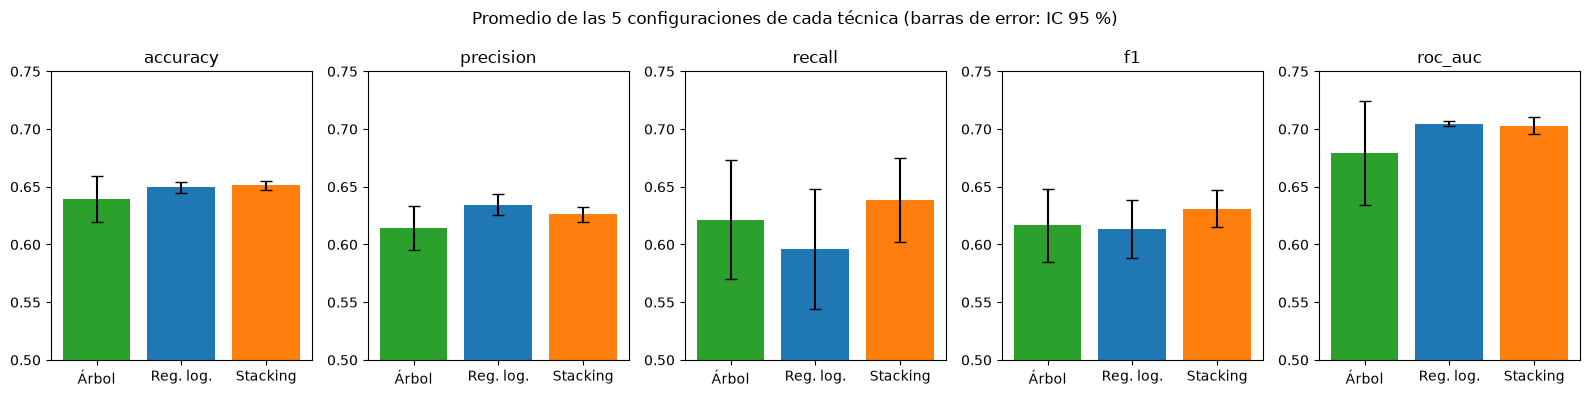

In [8]:
# Promedio de cada técnica con su IC 95 %
fig, axes = plt.subplots(1, len(METRICAS), figsize=(16, 4))
tecnicas = ['Árbol de decisión', 'Regresión logística', 'Stacking']
colores = ['tab:green', 'tab:blue', 'tab:orange']
for ax, m in zip(axes, METRICAS):
    medias = [promedios.loc[m, (t, 'media')] for t in tecnicas]
    errores = [medias[i] - promedios.loc[m, (t, 'IC95 inf')] for i, t in enumerate(tecnicas)]
    ax.bar(range(3), medias, yerr=errores, capsize=4, color=colores)
    ax.set_xticks(range(3), ['Árbol', 'Reg. log.', 'Stacking'])
    ax.set_ylim(0.5, 0.75)
    ax.set_title(m)
fig.suptitle('Promedio de las 5 configuraciones de cada técnica (barras de error: IC 95 %)')
plt.tight_layout()
plt.show()

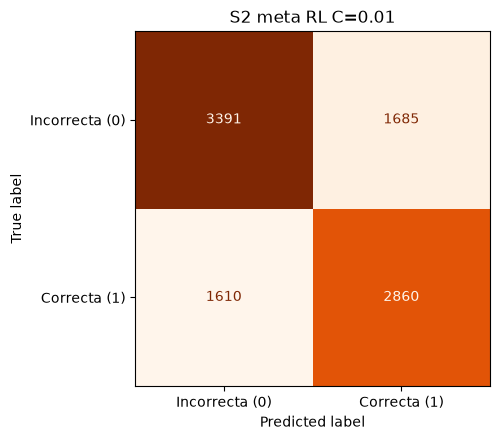

In [9]:
# Matriz de confusión del mejor Stacking (según AUC)
mejor_stack = res_stack['roc_auc'].idxmax()
y_pred = cross_val_predict(crear_pipeline(stackings[mejor_stack]), X, y, cv=cv)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(y, y_pred, display_labels=['Incorrecta (0)', 'Correcta (1)'],
                                        cmap='Oranges', colorbar=False, ax=ax)
ax.set_title(mejor_stack)
plt.tight_layout()
plt.show()

## 7. ¿A qué modelos base les hace caso el meta-modelo?

Se entrena S1 con todos los datos (solo para interpretar, no para evaluar) y se grafican los coeficientes de su meta-modelo. Un coeficiente más alto indica que el meta-modelo le da más importancia a la probabilidad que predice ese modelo base.

Como los modelos base predicen cosas muy parecidas entre sí, los coeficientes se "reparten" entre ellos: conviene leerlos como una tendencia, no como una medida exacta de importancia.

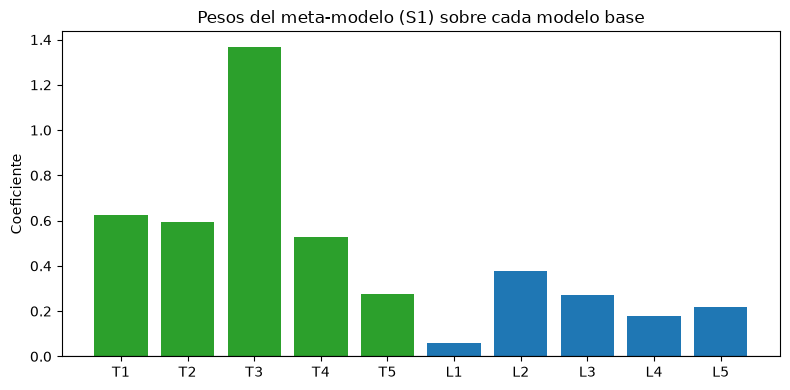

,T1,T2,T3,T4,T5,L1,L2,L3,L4,L5
peso,0.62,0.6,1.37,0.53,0.27,0.06,0.38,0.27,0.18,0.22


In [10]:
s1 = crear_pipeline(stackings['S1 meta RL C=1']).fit(X, y)
pesos = pd.Series(s1[-1].final_estimator_.coef_[0], index=[n for n, _ in modelos_base])

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(pesos.index, pesos.values, color=['tab:green'] * 5 + ['tab:blue'] * 5)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Pesos del meta-modelo (S1) sobre cada modelo base')
ax.set_ylabel('Coeficiente')
plt.tight_layout()
plt.show()

display(pesos.round(2).to_frame('peso').T)

In [11]:
# Se guardan los resultados para el informe
res_stack.to_csv(RESULTADOS / 'resultados_tarea3.csv')
promedios.to_csv(RESULTADOS / 'promedios_tarea3.csv')
print('Guardado en', RESULTADOS.relative_to(RAIZ))

Guardado en resultados


## 8. Conclusiones